# GPU-resident CUDA Hare Escape Optimization (HEO) benchmark (Google Colab)

Compares **sequential CPU**, **OpenMP CPU** and **CUDA GPU** implementations of the Hare Escape Optimization
algorithm (Alsamee & Ramezani, *Scientific Reports* 15:26405, 2025) on the same benchmark functions, with identical
search equations and an identical counter-based RNG (same seed → same trajectory on every back-end).

**In Colab:** Runtime → Change runtime type → T4 GPU, then run the cells top to bottom. The notebook stops if CUDA tools or an NVIDIA GPU are unavailable (set `REQUIRE_GPU = False` in section 1 to run CPU-only).

**What executes on the GPU:** population/velocity initialization, Levy-flight candidate generation, objective evaluation, a stable radix sort (CUB) for the *merge old + new → keep best N* step, and the gather of the survivors. Arrays stay in device memory for the whole run; only the final best fitness is copied back.

**Interpretation notes (the paper's pseudocode is under-specified):**
* Eq. 4 is `X' = X + (Maxit/t)·V + L·(X+V)·r`, `V' = 0.95·V`. The literal `Maxit/t` grows large early, so the default coefficient is `(T−t+1)/T` (1 → 0). Rebuild with `-DHEO_LITERAL_SCALE` for the literal version.
* `L` is a Mantegna Levy step (β = 1.5), unscaled; positions are clamped to the bounds; selection is elitist (merge, stable sort, keep best N).
* CEC 2015 needs the official shift/rotation data, so this notebook uses the paper's F16–F19 and F24–F30 plus Ackley, Griewank, Rosenbrock. Several formulas printed in the paper contain typos (Easom, Beale, Schaffer N.2); the standard forms are used here.
* The update term `L·(X+V)·r` scales with the position itself, which favours optima at the origin. The `--shift` runs below move the optimum away from the origin to expose this.

In [12]:
import os, shutil, subprocess, time
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO

print("nvidia-smi:", shutil.which("nvidia-smi"))
print("nvcc:", shutil.which("nvcc"))
if shutil.which("nvidia-smi") is None:
    raise RuntimeError("No NVIDIA GPU detected. Choose Runtime > Change runtime type > GPU.")
if shutil.which("nvcc") is None:
    raise RuntimeError("nvcc is unavailable in this runtime. Restart after selecting GPU or use a Colab runtime with CUDA Toolkit.")
subprocess.run(["nvidia-smi"], check=True)


nvidia-smi: /opt/bin/nvidia-smi
nvcc: /usr/local/cuda/bin/nvcc


CompletedProcess(args=['nvidia-smi'], returncode=0)

## 1. Select an NVIDIA GPU runtime

In [1]:
import os, shutil, subprocess, time, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REQUIRE_GPU = True      # set False to run only the sequential + OpenMP versions

HAS_GPU = shutil.which("nvidia-smi") is not None and shutil.which("nvcc") is not None
print("nvidia-smi:", shutil.which("nvidia-smi"))
print("nvcc:", shutil.which("nvcc"))
if REQUIRE_GPU and not HAS_GPU:
    raise RuntimeError("No NVIDIA GPU / nvcc found. Choose Runtime > Change runtime type > T4 GPU and restart.")
if HAS_GPU:
    subprocess.run(["nvidia-smi"], check=True)
print("CPU cores visible:", os.cpu_count())

nvidia-smi: /opt/bin/nvidia-smi
nvcc: /usr/local/cuda/bin/nvcc
CPU cores visible: 2


## 2. Write the source files
All sources are embedded, so no uploads are needed. `heo_common.h` holds the RNG, Levy flight, HEO update rule and benchmark functions shared by all three versions.

In [2]:
%%writefile heo_common.h
// heo_common.h - shared by the seq / OpenMP / CUDA builds.
// RNG, Levy flight, HEO update rule and benchmark functions live here so all
// three versions execute *exactly* the same math (counter-based RNG => results
// are reproducible and comparable across back-ends).
#pragma once
#include <cstdint>
#include <cmath>
#include <cstdio>
#include <cstdlib>
#include <cstring>
#include <string>
#include <vector>

#ifdef __CUDACC__
#define HD __host__ __device__
#else
#define HD
#endif

#ifdef USE_FLOAT
typedef float real;          // storage type of positions/velocities
#else
typedef double real;
#endif

#define HEO_PI 3.14159265358979323846

// ---------------------------------------------------------------- RNG
// Stateless counter-based RNG (splitmix64). u01(seed, iter, element, stream)
// -> uniform in the OPEN interval (0,1). Same value on CPU and GPU.
HD inline uint64_t mix64(uint64_t z) {
  z += 0x9E3779B97F4A7C15ULL;
  z = (z ^ (z >> 30)) * 0xBF58476D1CE4E5B9ULL;
  z = (z ^ (z >> 27)) * 0x94D049BB133111EBULL;
  return z ^ (z >> 31);
}
HD inline double u01(uint64_t seed, uint64_t a, uint64_t b, uint64_t c) {
  uint64_t h = mix64(seed ^ mix64(a ^ mix64(b ^ mix64(c))));
  return ((double)(h >> 11) + 0.5) * (1.0 / 9007199254740992.0);
}
// streams: 0=r  1..4=Levy  5=init x  6=init v  7=shift  9=quartic noise

// Levy flight step, Mantegna's algorithm, beta = 1.5
HD inline double levy_step(uint64_t seed, uint64_t t, uint64_t e, double sigma) {
  double u1 = u01(seed, t, e, 1), u2 = u01(seed, t, e, 2);
  double u3 = u01(seed, t, e, 3), u4 = u01(seed, t, e, 4);
  double nu = sqrt(-2.0 * log(u1)) * cos(2.0 * HEO_PI * u2) * sigma;
  double nv = sqrt(-2.0 * log(u3)) * cos(2.0 * HEO_PI * u4);
  double an = fabs(nv); if (an < 1e-12) an = 1e-12;
  return nu / pow(an, 1.0 / 1.5);
}
static inline double levy_sigma_host(double beta = 1.5) {
  return pow(tgamma(1 + beta) * sin(HEO_PI * beta / 2) /
             (tgamma((1 + beta) / 2) * beta * pow(2.0, (beta - 1) / 2)), 1 / beta);
}

// ---------------------------------------------------------------- HEO update
// Paper Eq.(4):  X' = X + (Maxit/t) V + L (X+V) r ,   V' = damping * V
// Default coefficient: vrc*(T-t+1)/T  (decreasing 1 -> 0, i.e. "distance reduction").
// Compile with -DHEO_LITERAL_SCALE to use the literal Maxit/t from the paper.
HD inline void heo_step(real x, real v, int t, int T, double vrc, double damp,
                        double lo, double hi, real L, real r, real* xn, real* vn) {
#ifdef HEO_LITERAL_SCALE
  real coef = (real)(vrc * (double)T / (double)t);
#else
  real coef = (real)(vrc * (double)(T - t + 1) / (double)T);
#endif
  real xx = x + coef * v + L * (x + v) * r;
  if (xx < (real)lo) xx = (real)lo;
  if (xx > (real)hi) xx = (real)hi;
  *xn = xx;
  *vn = (real)(damp * (double)v);
}

// ---------------------------------------------------------------- benchmarks
struct FuncInfo { const char* name; double lo, hi, fmin; int fixed_dim; int shiftable; };
static const FuncInfo FUNCS[] = {
  {"F16_StepSphere",  -100,  100, 0,          0, 1},
  {"F17_Quartic",     -1.28, 1.28, 0,         0, 1},   // + U[0,1) noise
  {"F18_Schwefel",    -500,  500, 0,          0, 0},   // offset so fmin = 0
  {"F19_Rastrigin",   -5.12, 5.12, 0,         0, 1},
  {"Ackley",          -32,   32,  0,          0, 1},
  {"Griewank",        -600,  600, 0,          0, 1},
  {"Rosenbrock",      -30,   30,  0,          0, 0},
  {"F24_Bohachevsky", -100,  100, 0,          2, 0},
  {"F25_Booth",       -10,   10,  0,          2, 0},
  {"F26_Matyas",      -10,   10,  0,          2, 0},
  {"F27_Easom",       -100,  100, -1,         2, 0},
  {"F28_Beale",       -4.5,  4.5, 0,          2, 0},
  {"F29_SchafferN2",  -100,  100, 0,          2, 0},
  {"F30_SixHumpCamel",-2,    2,   -1.0316285, 2, 0},
};
static const int NFUNCS = (int)(sizeof(FUNCS) / sizeof(FUNCS[0]));

HD inline uint64_t shift_seed(int fid) { return 0xC0FFEEULL + (uint64_t)fid; }

// Wraps a coordinate accessor and (optionally) applies a fixed shift o_i
// (|o_i| <= 40% of half-range) so the optimum is NOT at the origin.
template <class A> struct ShiftAcc {
  A a; int on; uint64_t sseed; double half;
  HD double operator()(int i) const {
    double z = (double)a(i);
    if (on) z -= 0.4 * (2.0 * u01(sseed, 0, (uint64_t)i, 7) - 1.0) * half;
    return z;
  }
};

template <class A>
HD inline double bench_eval(int id, int D, A z, double noise) {
  double s = 0.0;
  switch (id) {
    case 0: for (int i = 0; i < D; i++) { double f = floor(z(i) + 0.5); s += f * f; } return s;
    case 1: for (int i = 0; i < D; i++) { double v = z(i); s += (i + 1) * v * v * v * v; } return s + noise;
    case 2: s = 418.9828872724337 * D;
            for (int i = 0; i < D; i++) { double v = z(i); s -= v * sin(sqrt(fabs(v))); } return s;
    case 3: for (int i = 0; i < D; i++) { double v = z(i); s += v * v - 10.0 * cos(2 * HEO_PI * v) + 10.0; } return s;
    case 4: { double s1 = 0, s2 = 0;
            for (int i = 0; i < D; i++) { double v = z(i); s1 += v * v; s2 += cos(2 * HEO_PI * v); }
            return -20.0 * exp(-0.2 * sqrt(s1 / D)) - exp(s2 / D) + 20.0 + 2.718281828459045; }
    case 5: { double p = 1.0;
            for (int i = 0; i < D; i++) { double v = z(i); s += v * v; p *= cos(v / sqrt(i + 1.0)); }
            return 1.0 + s / 4000.0 - p; }
    case 6: for (int i = 0; i < D - 1; i++) { double a = z(i), b = z(i + 1);
              s += 100.0 * (b - a * a) * (b - a * a) + (a - 1.0) * (a - 1.0); } return s;
    case 7: { double x = z(0), y = z(1);
            return x * x + 2 * y * y - 0.3 * cos(3 * HEO_PI * x) - 0.4 * cos(4 * HEO_PI * y) + 0.7; }
    case 8: { double x = z(0), y = z(1); double a = x + 2 * y - 7, b = 2 * x + y - 5; return a * a + b * b; }
    case 9: { double x = z(0), y = z(1); return 0.26 * (x * x + y * y) - 0.48 * x * y; }
    case 10:{ double x = z(0), y = z(1);
            return -cos(x) * cos(y) * exp(-((x - HEO_PI) * (x - HEO_PI) + (y - HEO_PI) * (y - HEO_PI))); }
    case 11:{ double x = z(0), y = z(1);
            double a = 1.5 - x + x * y, b = 2.25 - x + x * y * y, c = 2.625 - x + x * y * y * y;
            return a * a + b * b + c * c; }
    case 12:{ double x = z(0), y = z(1); double r2 = x * x + y * y; double sn = sin(sqrt(r2));
            double d = 1.0 + 0.001 * r2; return 0.5 + (sn * sn - 0.5) / (d * d); }
    case 13:{ double x = z(0), y = z(1);
            return 4 * x * x - 2.1 * x * x * x * x + x * x * x * x * x * x / 3.0 + x * y + (-4 + 4 * y * y) * y * y; }
  }
  return 0.0;
}

// ---------------------------------------------------------------- params
struct Params {
  int fid = 0, dim = 30, pop = 30, iters = 500, runs = 10, shift = 0;
  uint64_t seed = 42;
  double vrc = 1.0, damp = 0.95;       // paper: velocity reduction coeff = 1, damping = 0.95
  double levy_scale = 1.0;             // paper uses raw L (scale 1); tunable via --levy-scale
  double lo = 0, hi = 0, sigma = 0;
};

Writing heo_common.h


In [3]:
%%writefile heo_main.h
// heo_main.h - common CLI + timing driver. Each back-end defines
//   static void   heo_backend_init();
//   static double heo_run(const Params&, uint64_t seed);   // returns best fitness
// and VERSION_NAME, then includes this file at the bottom.
#pragma once
#include "heo_common.h"
#include <chrono>

static void usage() {
  fprintf(stderr,
    "options: --func <id|all> --dim D --pop N --iters T --runs R --seed S\n"
    "         --shift  --levy-scale s  --no-header  --list\n");
}

int main(int argc, char** argv) {
  Params p; std::string func = "all"; bool header = true;
  for (int a = 1; a < argc; a++) {
    std::string s = argv[a];
    auto need = [&]() -> const char* {
      if (a + 1 >= argc) { fprintf(stderr, "missing value for %s\n", s.c_str()); exit(1); }
      return argv[++a]; };
    if (s == "--func") func = need();
    else if (s == "--dim") p.dim = atoi(need());
    else if (s == "--pop") p.pop = atoi(need());
    else if (s == "--iters") p.iters = atoi(need());
    else if (s == "--runs") p.runs = atoi(need());
    else if (s == "--seed") p.seed = strtoull(need(), 0, 10);
    else if (s == "--levy-scale") p.levy_scale = atof(need());
    else if (s == "--shift") p.shift = 1;
    else if (s == "--no-header") header = false;
    else if (s == "--list") { for (int k = 0; k < NFUNCS; k++) printf("%2d  %-18s [%g, %g]\n", k, FUNCS[k].name, FUNCS[k].lo, FUNCS[k].hi); return 0; }
    else { usage(); return 1; }
  }
  heo_backend_init();
  if (header) printf("version,func,dim,pop,iters,shift,run,best,time_ms\n");
  int f0 = 0, f1 = NFUNCS;
  if (func != "all") { f0 = atoi(func.c_str()); f1 = f0 + 1; if (f0 < 0 || f0 >= NFUNCS) { usage(); return 1; } }
  for (int fid = f0; fid < f1; fid++) {
    Params q = p; q.fid = fid; q.lo = FUNCS[fid].lo; q.hi = FUNCS[fid].hi;
    if (FUNCS[fid].fixed_dim) q.dim = FUNCS[fid].fixed_dim;
    q.shift = p.shift && FUNCS[fid].shiftable;
    q.sigma = levy_sigma_host();
    Params w = q; w.iters = 2; heo_run(w, 1);            // untimed warm-up (JIT, threads, CUDA ctx)
    for (int r = 0; r < p.runs; r++) {
      uint64_t seed = p.seed + 1000003ULL * (uint64_t)r;
      auto t0 = std::chrono::steady_clock::now();
      double f = heo_run(q, seed);
      auto t1 = std::chrono::steady_clock::now();
      double ms = std::chrono::duration<double, std::milli>(t1 - t0).count();
      printf("%s,%s,%d,%d,%d,%d,%d,%.12e,%.4f\n", VERSION_NAME, FUNCS[fid].name,
             q.dim, q.pop, q.iters, q.shift, r, f, ms);
      fflush(stdout);
    }
  }
  return 0;
}

Writing heo_main.h


In [4]:
%%writefile heo_seq.cpp
// Sequential reference implementation of Hare Escape Optimization.
#define VERSION_NAME "seq"
#include "heo_common.h"
#include <algorithm>
#include <numeric>

struct RowAcc { const real* p; HD real operator()(int i) const { return p[i]; } };
static void heo_backend_init() {}

static double heo_run(const Params& p, uint64_t seed) {
  const int N = p.pop, D = p.dim, M = 2 * N, T = p.iters;
  const size_t cnt = (size_t)M * D;
  std::vector<real> pos(cnt), vel(cnt), pos2(cnt), vel2(cnt);   // row j = hare j (AoS)
  std::vector<double> fit(M), fit2(M);
  std::vector<int> idx(M);
  const uint64_t sseed = shift_seed(p.fid); const double half = 0.5 * (p.hi - p.lo);
  auto eval = [&](const real* row, double noise) {
    ShiftAcc<RowAcc> s{RowAcc{row}, p.shift, sseed, half};
    return bench_eval(p.fid, D, s, noise); };

  for (int j = 0; j < N; j++) {
    for (int i = 0; i < D; i++) {
      uint64_t e = (uint64_t)j * D + i;
      pos[(size_t)j * D + i] = (real)(p.lo + (p.hi - p.lo) * u01(seed, 0, e, 5));
      vel[(size_t)j * D + i] = (real)(p.lo + (p.hi - p.lo) * u01(seed, 0, e, 6));
    }
    fit[j] = eval(&pos[(size_t)j * D], u01(seed, 0, j, 9));
  }
  for (int t = 1; t <= T; t++) {
    for (int j = 0; j < N; j++) {                       // candidate for each hare
      for (int i = 0; i < D; i++) {
        uint64_t e = (uint64_t)j * D + i;
        real L = (real)(levy_step(seed, t, e, p.sigma) * p.levy_scale);
        real r = (real)u01(seed, t, e, 0);
        heo_step(pos[(size_t)j * D + i], vel[(size_t)j * D + i], t, T, p.vrc, p.damp, p.lo, p.hi, L, r,
                 &pos[(size_t)(N + j) * D + i], &vel[(size_t)(N + j) * D + i]);
      }
      fit[N + j] = eval(&pos[(size_t)(N + j) * D], u01(seed, t, j, 9));
    }
    std::iota(idx.begin(), idx.end(), 0);               // merge old+new, keep best N (ties -> lower index)
    std::partial_sort(idx.begin(), idx.begin() + N, idx.end(),
        [&](int a, int b) { return fit[a] < fit[b] || (fit[a] == fit[b] && a < b); });
    for (int k = 0; k < N; k++) {
      int s = idx[k];
      memcpy(&pos2[(size_t)k * D], &pos[(size_t)s * D], D * sizeof(real));
      memcpy(&vel2[(size_t)k * D], &vel[(size_t)s * D], D * sizeof(real));
      fit2[k] = fit[s];
    }
    pos.swap(pos2); vel.swap(vel2); fit.swap(fit2);
  }
  return fit[0];
}
#include "heo_main.h"

Writing heo_seq.cpp


In [5]:
%%writefile heo_omp.cpp
// OpenMP implementation: update+evaluation, gather and merge-sort are all parallel.
#define VERSION_NAME "omp"
#include "heo_common.h"
#include <algorithm>
#include <parallel/algorithm>   // __gnu_parallel::sort (libstdc++, needs -fopenmp)
#include <omp.h>

struct RowAcc { const real* p; HD real operator()(int i) const { return p[i]; } };
static void heo_backend_init() { fprintf(stderr, "[omp] threads = %d\n", omp_get_max_threads()); }

static double heo_run(const Params& p, uint64_t seed) {
  const int N = p.pop, D = p.dim, M = 2 * N, T = p.iters;
  const size_t cnt = (size_t)M * D;
  std::vector<real> pos(cnt), vel(cnt), pos2(cnt), vel2(cnt);
  std::vector<double> fit(M), fit2(M);
  std::vector<int> idx(M);
  const uint64_t sseed = shift_seed(p.fid); const double half = 0.5 * (p.hi - p.lo);
  auto eval = [&](const real* row, double noise) {
    ShiftAcc<RowAcc> s{RowAcc{row}, p.shift, sseed, half};
    return bench_eval(p.fid, D, s, noise); };

  #pragma omp parallel for schedule(static)
  for (int j = 0; j < N; j++) {
    for (int i = 0; i < D; i++) {
      uint64_t e = (uint64_t)j * D + i;
      pos[(size_t)j * D + i] = (real)(p.lo + (p.hi - p.lo) * u01(seed, 0, e, 5));
      vel[(size_t)j * D + i] = (real)(p.lo + (p.hi - p.lo) * u01(seed, 0, e, 6));
    }
    fit[j] = eval(&pos[(size_t)j * D], u01(seed, 0, j, 9));
  }
  for (int t = 1; t <= T; t++) {
    #pragma omp parallel for schedule(static)
    for (int j = 0; j < N; j++) {
      for (int i = 0; i < D; i++) {
        uint64_t e = (uint64_t)j * D + i;
        real L = (real)(levy_step(seed, t, e, p.sigma) * p.levy_scale);
        real r = (real)u01(seed, t, e, 0);
        heo_step(pos[(size_t)j * D + i], vel[(size_t)j * D + i], t, T, p.vrc, p.damp, p.lo, p.hi, L, r,
                 &pos[(size_t)(N + j) * D + i], &vel[(size_t)(N + j) * D + i]);
      }
      fit[N + j] = eval(&pos[(size_t)(N + j) * D], u01(seed, t, j, 9));
    }
    #pragma omp parallel for schedule(static)
    for (int k = 0; k < M; k++) idx[k] = k;
    __gnu_parallel::sort(idx.begin(), idx.end(),        // strict total order => deterministic
        [&](int a, int b) { return fit[a] < fit[b] || (fit[a] == fit[b] && a < b); });
    #pragma omp parallel for schedule(static)
    for (int k = 0; k < N; k++) {
      int s = idx[k];
      memcpy(&pos2[(size_t)k * D], &pos[(size_t)s * D], D * sizeof(real));
      memcpy(&vel2[(size_t)k * D], &vel[(size_t)s * D], D * sizeof(real));
      fit2[k] = fit[s];
    }
    pos.swap(pos2); vel.swap(vel2); fit.swap(fit2);
  }
  return fit[0];
}
#include "heo_main.h"

Writing heo_omp.cpp


In [6]:
%%writefile heo_cuda.cu
// CUDA implementation. One thread per (hare, dimension) for update, one thread per hare for
// fitness evaluation, CUB radix sort (stable) for the merge/select step.
// Layout is dimension-major: element (hare j, dim i) at [i*M + j], M = 2N  => coalesced access.
// Columns [0,N) = parents, [N,2N) = candidates.
#define VERSION_NAME "cuda"
#include "heo_common.h"
#include <cuda_runtime.h>
#include <cub/cub.cuh>
#include <utility>

#define CK(x) do { cudaError_t e_ = (x); if (e_ != cudaSuccess) { \
  fprintf(stderr, "CUDA error '%s' at %s:%d\n", cudaGetErrorString(e_), __FILE__, __LINE__); exit(1); } } while (0)

struct ColAcc { const real* p; int stride; HD real operator()(int i) const { return p[(size_t)i * stride]; } };

__global__ void k_init(real* pos, real* vel, int N, int D, int M, uint64_t seed, double lo, double hi) {
  size_t tid = blockIdx.x * (size_t)blockDim.x + threadIdx.x; if (tid >= (size_t)N * D) return;
  int j = (int)(tid % N), i = (int)(tid / N); uint64_t e = (uint64_t)j * D + i;
  pos[(size_t)i * M + j] = (real)(lo + (hi - lo) * u01(seed, 0, e, 5));
  vel[(size_t)i * M + j] = (real)(lo + (hi - lo) * u01(seed, 0, e, 6));
}
__global__ void k_update(real* pos, real* vel, int N, int D, int M, uint64_t seed, int t, int T,
                         double vrc, double damp, double lo, double hi, double sigma, double lscale) {
  size_t tid = blockIdx.x * (size_t)blockDim.x + threadIdx.x; if (tid >= (size_t)N * D) return;
  int j = (int)(tid % N), i = (int)(tid / N); uint64_t e = (uint64_t)j * D + i;
  size_t a = (size_t)i * M + j, b = (size_t)i * M + N + j;
  real L = (real)(levy_step(seed, t, e, sigma) * lscale);
  real r = (real)u01(seed, t, e, 0);
  heo_step(pos[a], vel[a], t, T, vrc, damp, lo, hi, L, r, &pos[b], &vel[b]);
}
__global__ void k_eval(const real* pos, double* fit, int off, int N, int D, int M, int fid, int shift,
                       double lo, double hi, uint64_t seed, int t) {
  int j = blockIdx.x * blockDim.x + threadIdx.x; if (j >= N) return;
  ColAcc a{pos + off + j, M};
  ShiftAcc<ColAcc> s{a, shift, shift_seed(fid), 0.5 * (hi - lo)};
  fit[off + j] = bench_eval(fid, D, s, u01(seed, t, j, 9));
}
__global__ void k_iota(int* idx, int M) { int k = blockIdx.x * blockDim.x + threadIdx.x; if (k < M) idx[k] = k; }
__global__ void k_gather(const real* pos, const real* vel, real* pos2, real* vel2, const int* idx, int N, int D, int M) {
  size_t tid = blockIdx.x * (size_t)blockDim.x + threadIdx.x; if (tid >= (size_t)N * D) return;
  int j = (int)(tid % N), i = (int)(tid / N); int s = idx[j];
  pos2[(size_t)i * M + j] = pos[(size_t)i * M + s];
  vel2[(size_t)i * M + j] = vel[(size_t)i * M + s];
}

static void heo_backend_init() {
  CK(cudaFree(0));
  cudaDeviceProp pr; CK(cudaGetDeviceProperties(&pr, 0));
  fprintf(stderr, "[cuda] device = %s (%d SMs)\n", pr.name, pr.multiProcessorCount);
}

static double heo_run(const Params& p, uint64_t seed) {
  const int N = p.pop, D = p.dim, M = 2 * N, T = p.iters;
  const size_t cnt = (size_t)M * D;
  real *pos, *vel, *pos2, *vel2; double *fit, *fit2; int *idx_in, *idx_out;
  CK(cudaMalloc(&pos, cnt * sizeof(real)));  CK(cudaMalloc(&vel, cnt * sizeof(real)));
  CK(cudaMalloc(&pos2, cnt * sizeof(real))); CK(cudaMalloc(&vel2, cnt * sizeof(real)));
  CK(cudaMalloc(&fit, M * sizeof(double)));  CK(cudaMalloc(&fit2, M * sizeof(double)));
  CK(cudaMalloc(&idx_in, M * sizeof(int)));  CK(cudaMalloc(&idx_out, M * sizeof(int)));
  void* tmp = nullptr; size_t tmpb = 0;
  CK(cub::DeviceRadixSort::SortPairs(nullptr, tmpb, fit, fit2, idx_in, idx_out, M));
  CK(cudaMalloc(&tmp, tmpb));

  const int B = 256;
  const unsigned gND = (unsigned)(((size_t)N * D + B - 1) / B), gN = (N + B - 1) / B, gM = (M + B - 1) / B;
  k_init<<<gND, B>>>(pos, vel, N, D, M, seed, p.lo, p.hi);
  k_eval<<<gN, B>>>(pos, fit, 0, N, D, M, p.fid, p.shift, p.lo, p.hi, seed, 0);
  for (int t = 1; t <= T; t++) {
    k_update<<<gND, B>>>(pos, vel, N, D, M, seed, t, T, p.vrc, p.damp, p.lo, p.hi, p.sigma, p.levy_scale);
    k_eval<<<gN, B>>>(pos, fit, N, N, D, M, p.fid, p.shift, p.lo, p.hi, seed, t);
    k_iota<<<gM, B>>>(idx_in, M);
    CK(cub::DeviceRadixSort::SortPairs(tmp, tmpb, fit, fit2, idx_in, idx_out, M));   // stable
    k_gather<<<gND, B>>>(pos, vel, pos2, vel2, idx_out, N, D, M);
    std::swap(pos, pos2); std::swap(vel, vel2); std::swap(fit, fit2);
  }
  CK(cudaGetLastError());
  double best; CK(cudaMemcpy(&best, fit, sizeof(double), cudaMemcpyDeviceToHost));   // implicit sync
  cudaFree(pos); cudaFree(vel); cudaFree(pos2); cudaFree(vel2); cudaFree(fit); cudaFree(fit2);
  cudaFree(idx_in); cudaFree(idx_out); cudaFree(tmp);
  return best;
}
#include "heo_main.h"

Writing heo_cuda.cu


## 3. Compile sequential, OpenMP and CUDA programs
Flags `-ffp-contract=off` (CPU) and `--fmad=false` (GPU) keep floating-point behaviour as close as possible across back-ends so the parity check in section 5 is meaningful.

In [7]:
def sh(cmd):
    print("$", " ".join(cmd))
    r = subprocess.run(cmd, capture_output=True, text=True)
    print(r.stdout + r.stderr)
    r.check_returncode()

sh(["g++", "-O3", "-std=c++17", "-ffp-contract=off", "heo_seq.cpp", "-o", "heo_seq"])
sh(["g++", "-O3", "-std=c++17", "-ffp-contract=off", "-fopenmp", "heo_omp.cpp", "-o", "heo_omp"])
if HAS_GPU:
    cc = subprocess.run(["nvidia-smi", "--query-gpu=compute_cap", "--format=csv,noheader"],
                        capture_output=True, text=True).stdout.strip().split("\n")[0].replace(".", "")
    sh(["nvcc", "-O3", "-std=c++17", f"-arch=sm_{cc}", "--fmad=false", "heo_cuda.cu", "-o", "heo_cuda"])
print("Build finished.")

$ g++ -O3 -std=c++17 -ffp-contract=off heo_seq.cpp -o heo_seq

$ g++ -O3 -std=c++17 -ffp-contract=off -fopenmp heo_omp.cpp -o heo_omp

$ nvcc -O3 -std=c++17 -arch=sm_75 --fmad=false heo_cuda.cu -o heo_cuda

Build finished.


## 4. Run benchmark trials

All implementations use the same functions, dimension, population, iterations and repeats. Each repeat uses a different seed, but repeat *k* uses the **same** seed in every implementation. Timing is end-to-end wall-clock per run (including GPU buffer allocation, excluding an untimed warm-up run).

The 2-D functions (F24–F30) are fixed at dimension 2 by definition; they are tiny and dominated by launch overhead, so they are reported separately from the scalable functions.

In [8]:
# Recommended first run; increase after checking that everything works.
D = 100
POP = 1024
ITERS = 300
REPEATS = 3
OMP_THREADS = os.cpu_count()      # change to the number of CPU threads you want to test
# Larger run (slow for the sequential version):  D=500, POP=2048, ITERS=1000

SCALABLE = ["F16_StepSphere", "F17_Quartic", "F18_Schwefel", "F19_Rastrigin", "Ackley", "Griewank", "Rosenbrock"]
SHIFTABLE_IDS = [0, 1, 3, 4, 5]   # functions that support --shift (optimum moved away from the origin)
IMPLS = ["seq", "omp"] + (["cuda"] if HAS_GPU else [])
LABEL = {"seq": "CPU", "omp": "OpenMP", "cuda": "CUDA GPU"}

def run(exe, func="all", extra=(), **over):
    cfg = dict(dim=D, pop=POP, iters=ITERS, runs=REPEATS); cfg.update(over)
    cmd = [f"./heo_{exe}", "--func", str(func), "--dim", str(cfg["dim"]), "--pop", str(cfg["pop"]),
           "--iters", str(cfg["iters"]), "--runs", str(cfg["runs"])] + list(extra)
    env = os.environ.copy(); env["OMP_NUM_THREADS"] = str(OMP_THREADS)
    print("Running:", " ".join(cmd))
    p = subprocess.run(cmd, capture_output=True, text=True, env=env)
    if p.stderr.strip(): print(p.stderr.strip())
    if p.returncode != 0:
        print(p.stdout); p.check_returncode()
    return pd.read_csv(io.StringIO(p.stdout))

frames = []
for v in IMPLS:                                   # (a) optimum at the origin
    frames.append(run(v))
for v in IMPLS:                                   # (b) shifted optimum
    for fid in SHIFTABLE_IDS:
        frames.append(run(v, func=fid, extra=["--shift"]))
results = pd.concat(frames, ignore_index=True)
results["seconds"] = results["time_ms"] / 1000.0
results["implementation"] = results["version"].map(LABEL)
display(results.head(10))
print("rows:", len(results), "| OpenMP threads:", OMP_THREADS)

Running: ./heo_seq --func all --dim 100 --pop 1024 --iters 300 --runs 3
Running: ./heo_omp --func all --dim 100 --pop 1024 --iters 300 --runs 3
[omp] threads = 2
Running: ./heo_cuda --func all --dim 100 --pop 1024 --iters 300 --runs 3
[cuda] device = Tesla T4 (40 SMs)
Running: ./heo_seq --func 0 --dim 100 --pop 1024 --iters 300 --runs 3 --shift
Running: ./heo_seq --func 1 --dim 100 --pop 1024 --iters 300 --runs 3 --shift
Running: ./heo_seq --func 3 --dim 100 --pop 1024 --iters 300 --runs 3 --shift
Running: ./heo_seq --func 4 --dim 100 --pop 1024 --iters 300 --runs 3 --shift
Running: ./heo_seq --func 5 --dim 100 --pop 1024 --iters 300 --runs 3 --shift
Running: ./heo_omp --func 0 --dim 100 --pop 1024 --iters 300 --runs 3 --shift
[omp] threads = 2
Running: ./heo_omp --func 1 --dim 100 --pop 1024 --iters 300 --runs 3 --shift
[omp] threads = 2
Running: ./heo_omp --func 3 --dim 100 --pop 1024 --iters 300 --runs 3 --shift
[omp] threads = 2
Running: ./heo_omp --func 4 --dim 100 --pop 1024 --it

,version,func,dim,pop,iters,shift,run,best,time_ms,seconds,implementation
0,seq,F16_StepSphere,100,1024,300,0,0,13363.000000,4027.5891,4.027589,CPU
1,seq,F16_StepSphere,100,1024,300,0,1,14217.000000,4037.8894,4.037889,CPU
2,seq,F16_StepSphere,100,1024,300,0,2,14093.000000,4037.4759,4.037476,CPU
3,seq,F17_Quartic,100,1024,300,0,0,60.598363,4079.3814,4.079381,CPU
4,seq,F17_Quartic,100,1024,300,0,1,65.560671,5434.2402,5.434240,CPU
5,seq,F17_Quartic,100,1024,300,0,2,38.087060,4065.4996,4.065500,CPU
6,seq,F18_Schwefel,100,1024,300,0,0,31690.763913,4630.4374,4.630437,CPU
7,seq,F18_Schwefel,100,1024,300,0,1,32281.182408,4777.7270,4.777727,CPU
8,seq,F18_Schwefel,100,1024,300,0,2,29689.624833,4677.1159,4.677116,CPU
9,seq,F19_Rastrigin,100,1024,300,0,0,620.547891,4672.4380,4.672438,CPU


rows: 171 | OpenMP threads: 2


## 5. Summary table, speedup and parity check

Speedup is `sequential time / parallel time` (>1 means the parallel version is faster). The parity check confirms all back-ends reach (nearly) the same best value for the same seed — if it fails, a speedup number is meaningless.

In [9]:
keys = ["func", "shift"]
summary = (results.groupby(keys + ["version"])
           .agg(mean_best=("best", "mean"), std_best=("best", "std"),
                mean_seconds=("seconds", "mean"), std_seconds=("seconds", "std"))
           .reset_index())
times  = summary.pivot_table(index=keys, columns="version", values="mean_seconds")
scores = summary.pivot_table(index=keys, columns="version", values="mean_best")
stds   = summary.pivot_table(index=keys, columns="version", values="std_best")

comparison = pd.DataFrame(index=times.index)
for v in IMPLS:            comparison[f"{LABEL[v]} mean s"] = times[v]
for v in IMPLS[1:]:        comparison[f"Speedup CPU/{LABEL[v]}"] = times["seq"] / times[v]
for v in IMPLS:            comparison[f"{LABEL[v]} mean score"] = scores[v]
comparison["score std (CPU)"] = stds["seq"]

print("=== Scalable functions (D = %d, N = %d, iterations = %d) ===" % (D, POP, ITERS))
display(comparison.loc[comparison.index.get_level_values("func").isin(SCALABLE)])
print("=== Fixed 2-D functions (launch-overhead dominated) ===")
display(comparison.loc[~comparison.index.get_level_values("func").isin(SCALABLE)])

# ---- parity: same seed => same best value on every back-end
rk = keys + ["run"]
base = results[results.version == "seq"].set_index(rk)["best"]
for v in IMPLS[1:]:
    o = results[results.version == v].set_index(rk)["best"]
    diff = (o - base).abs()
    rel = diff / (1.0 + base.abs())
    print(f"parity CPU vs {LABEL[v]}: max |delta best| = {diff.max():.3e}, max relative = {rel.max():.3e}, "
          f"runs with rel. diff > 1e-6: {(rel > 1e-6).sum()} / {len(rel)}")

results.to_csv("heo_raw_trials.csv", index=False)
summary.to_csv("heo_summary.csv", index=False)
comparison.to_csv("heo_comparison.csv")
print("Saved heo_raw_trials.csv, heo_summary.csv, heo_comparison.csv")

=== Scalable functions (D = 100, N = 1024, iterations = 300) ===


CPU mean s  OpenMP mean s  CUDA GPU mean s  \
func           shift                                               
Ackley         0        4.563935       3.490057         0.146132   
               1        5.348067       4.060881         0.170318   
F16_StepSphere 0        4.034318       3.101837         0.136968   
               1        4.304320       3.330249         0.163255   
F17_Quartic    0        4.526374       3.061882         0.101014   
               1        4.160331       3.337851         0.124077   
F18_Schwefel   0        4.695093       3.548340         0.163561   
F19_Rastrigin  0        4.668664       3.546741         0.150434   
               1        5.305657       3.925397         0.173374   
Griewank       0        4.871899       3.684786         0.185908   
               1        5.408194       3.975828         0.212966   
Rosenbrock     0        3.940398       3.058227         0.106650   

                      Speedup CPU/OpenMP  Speedup CPU/CUDA GPU  \
func           shift                                             
Ackley         0                1.307696             31.231558   
               1                1.316972             31.400547   
F16_StepSphere 0                1.300622             29.454429   
               1                1.292492             26.365690   
F17_Quartic    0                1.478298             44.809385   
               1                1.246410             33.530358   
F18_Schwefel   0                1.323180             28.705400   
F19_Rastrigin  0                1.316325             31.034593   
               1                1.351623             30.602430   
Griewank       0                1.322166             26.205988   
               1                1.360269             25.394581   
Rosenbrock     0                1.288458             36.947154   

                      CPU mean score  OpenMP mean score  CUDA GPU mean score  \
func           shift                                                           
Ackley         0        2.035351e+01       2.035351e+01         2.035351e+01   
               1        1.741665e+01       1.741665e+01         1.741665e+01   
F16_StepSphere 0        1.389100e+04       1.389100e+04         1.389100e+04   
               1        5.894367e+04       5.894367e+04         5.894367e+04   
F17_Quartic    0        5.474870e+01       5.474870e+01         5.474870e+01   
               1        1.417062e+02       1.417062e+02         1.417062e+02   
F18_Schwefel   0        3.122052e+04       3.122052e+04         3.122052e+04   
F19_Rastrigin  0        4.909384e+02       4.909384e+02         4.909384e+02   
               1        9.675746e+02       9.675746e+02         9.675746e+02   
Griewank       0        7.864473e+01       7.864473e+01         7.864473e+01   
               1        5.701679e+02       5.701679e+02         5.701679e+02   
Rosenbrock     0        3.954129e+07       3.954129e+07         3.954129e+07   

                      score std (CPU)  
func           shift                   
Ackley         0         3.223783e-02  
               1         3.613551e-01  
F16_StepSphere 0         4.614456e+02  
               1         6.658118e+02  
F17_Quartic    0         1.464117e+01  
               1         3.499168e+01  
F18_Schwefel   0         1.358266e+03  
F19_Rastrigin  0         1.138916e+02  
               1         3.649434e+01  
Griewank       0         1.617839e+01  
               1         3.935629e+01  
Rosenbrock     0         2.878561e+07

=== Fixed 2-D functions (launch-overhead dominated) ===


,,CPU mean s,OpenMP mean s,CUDA GPU mean s,Speedup CPU/OpenMP,Speedup CPU/CUDA GPU,CPU mean score,OpenMP mean score,CUDA GPU mean score,score std (CPU)
func,shift,,,,,,,,,
F24_Bohachevsky,0,0.124775,0.099265,0.019315,1.256995,6.460152,2.545767e-06,2.545767e-06,2.545767e-06,2.254292e-06
F25_Booth,0,0.110227,0.103265,0.018249,1.067414,6.040082,9.046627e-06,9.046627e-06,9.046627e-06,5.270254e-06
F26_Matyas,0,0.111685,0.091914,0.018154,1.215111,6.152234,1.716627e-09,1.716627e-09,1.716627e-09,2.466070e-09
F27_Easom,0,0.127640,0.102035,0.019805,1.250935,6.444889,-9.999853e-01,-9.999853e-01,-9.999853e-01,2.198498e-05
F28_Beale,0,0.115354,0.097472,0.018355,1.183456,6.284492,4.077100e-06,4.077100e-06,4.077100e-06,3.105196e-06
F29_SchafferN2,0,0.126571,0.096101,0.019252,1.317062,6.574608,9.730359e-07,9.730359e-07,9.730359e-07,7.528971e-07
F30_SixHumpCamel,0,0.113237,0.090346,0.018742,1.253371,6.041995,-1.031628e+00,-1.031628e+00,-1.031628e+00,1.350209e-07


parity CPU vs OpenMP: max |delta best| = 0.000e+00, max relative = 0.000e+00, runs with rel. diff > 1e-6: 0 / 57
parity CPU vs CUDA GPU: max |delta best| = 9.990e-12, max relative = 1.501e-13, runs with rel. diff > 1e-6: 0 / 57
Saved heo_raw_trials.csv, heo_summary.csv, heo_comparison.csv


## 6. Comparison graphs
Score plots are separated per benchmark because objective-value scales differ substantially.

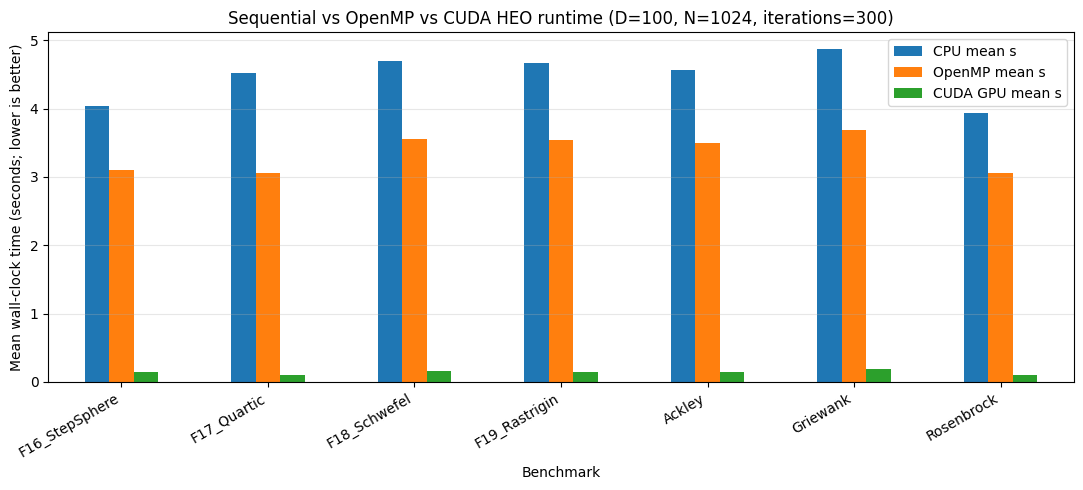

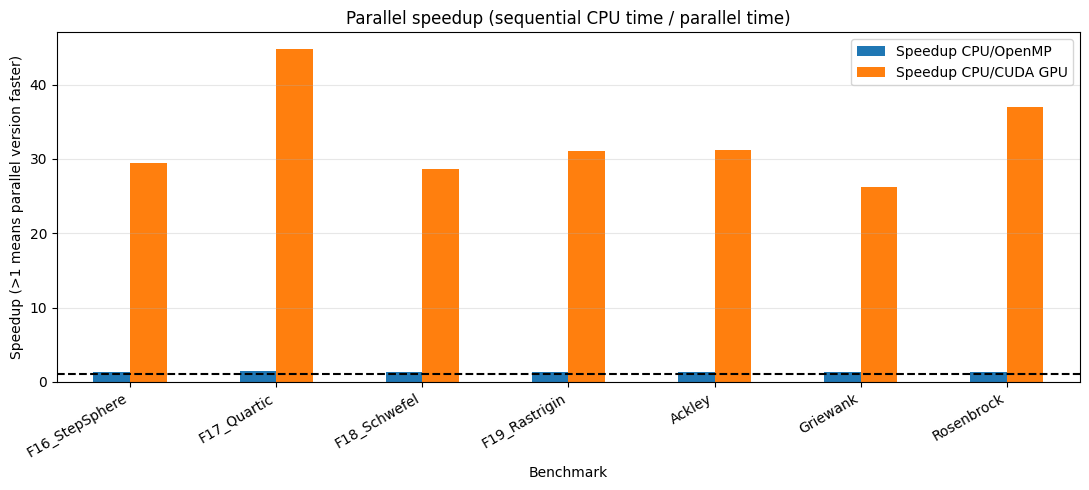

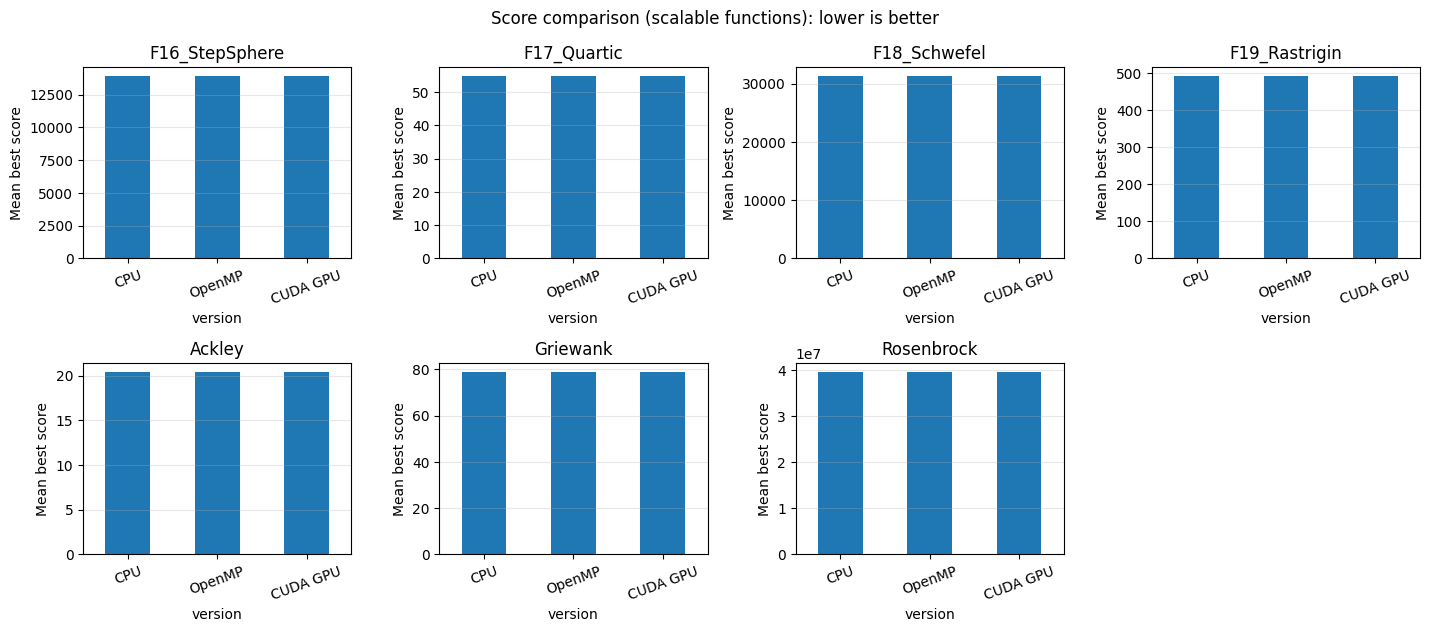

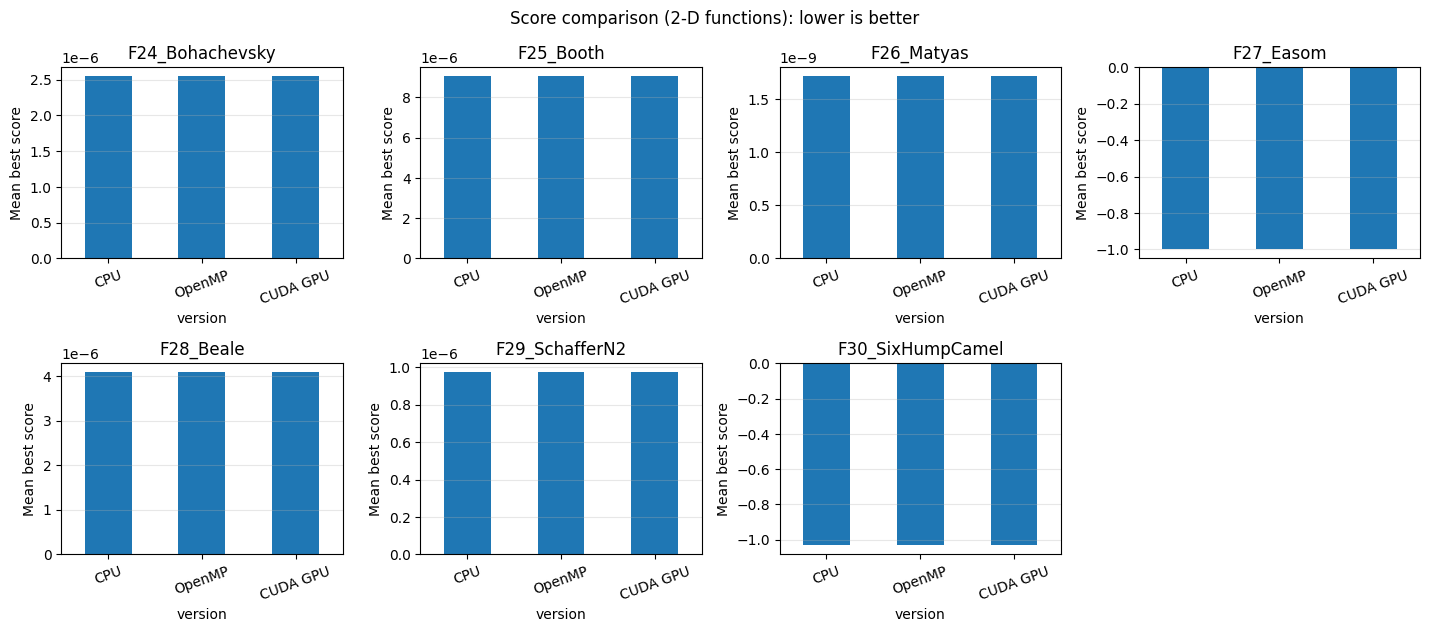

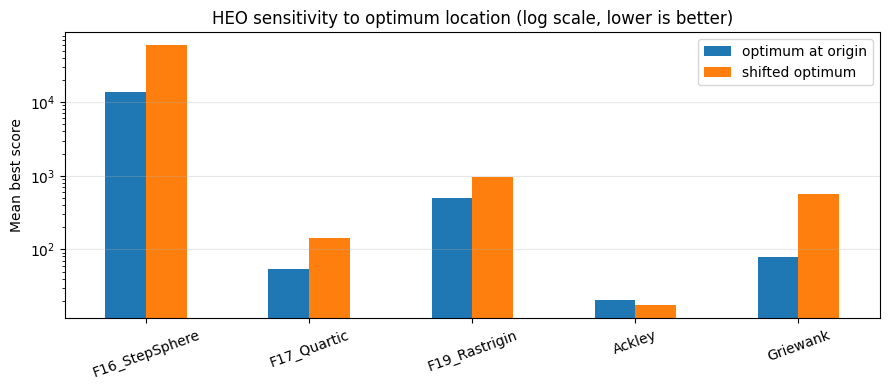

In [10]:
c0 = comparison.xs(0, level="shift")
sc = c0.loc[[f for f in SCALABLE if f in c0.index]]

ax = sc[[f"{LABEL[v]} mean s" for v in IMPLS]].plot(kind="bar", figsize=(11, 5))
ax.set_title(f"Sequential vs OpenMP vs CUDA HEO runtime (D={D}, N={POP}, iterations={ITERS})")
ax.set_ylabel("Mean wall-clock time (seconds; lower is better)"); ax.set_xlabel("Benchmark")
ax.grid(axis="y", alpha=0.3); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

sp_cols = [f"Speedup CPU/{LABEL[v]}" for v in IMPLS[1:]]
ax = sc[sp_cols].plot(kind="bar", figsize=(11, 5))
ax.axhline(1.0, linestyle="--", color="k")
ax.set_title("Parallel speedup (sequential CPU time / parallel time)")
ax.set_ylabel("Speedup (>1 means parallel version faster)"); ax.set_xlabel("Benchmark")
ax.grid(axis="y", alpha=0.3); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

def score_grid(df_scores, funcs, title, ncols=4):
    nrows = int(np.ceil(len(funcs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.2 * nrows))
    for ax, fn in zip(np.atleast_1d(axes).flat, funcs):
        df_scores.loc[fn, [v for v in IMPLS]].rename(LABEL).plot(kind="bar", ax=ax)
        ax.set_title(fn); ax.set_ylabel("Mean best score"); ax.tick_params(axis="x", rotation=20); ax.grid(axis="y", alpha=0.3)
    for ax in np.atleast_1d(axes).flat[len(funcs):]: ax.set_visible(False)
    fig.suptitle(title); plt.tight_layout(); plt.show()

s0 = scores.xs(0, level="shift")
score_grid(s0, [f for f in SCALABLE if f in s0.index], "Score comparison (scalable functions): lower is better")
score_grid(s0, [f for f in s0.index if f not in SCALABLE], "Score comparison (2-D functions): lower is better")

# optimum at the origin vs shifted optimum (CPU back-end, same seeds)
sh_f = [f for f in SCALABLE if (f, 1) in scores.index]
cmpdf = pd.DataFrame({"optimum at origin": [scores.loc[(f, 0), "seq"] for f in sh_f],
                      "shifted optimum":   [scores.loc[(f, 1), "seq"] for f in sh_f]}, index=sh_f)
ax = cmpdf.plot(kind="bar", figsize=(9, 4), logy=True)
ax.set_title("HEO sensitivity to optimum location (log scale, lower is better)")
ax.set_ylabel("Mean best score"); ax.grid(axis="y", alpha=0.3); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

## 7. Scaling experiments

GPUs only win once there is enough parallel work. These sweeps use Rastrigin (function id 3) and show where CUDA / OpenMP overtake the sequential code.

Running: ./heo_seq --func 3 --dim 100 --pop 64 --iters 100 --runs 3
Running: ./heo_omp --func 3 --dim 100 --pop 64 --iters 100 --runs 3
[omp] threads = 2
Running: ./heo_cuda --func 3 --dim 100 --pop 64 --iters 100 --runs 3
[cuda] device = Tesla T4 (40 SMs)
Running: ./heo_seq --func 3 --dim 100 --pop 256 --iters 100 --runs 3
Running: ./heo_omp --func 3 --dim 100 --pop 256 --iters 100 --runs 3
[omp] threads = 2
Running: ./heo_cuda --func 3 --dim 100 --pop 256 --iters 100 --runs 3
[cuda] device = Tesla T4 (40 SMs)
Running: ./heo_seq --func 3 --dim 100 --pop 1024 --iters 100 --runs 3
Running: ./heo_omp --func 3 --dim 100 --pop 1024 --iters 100 --runs 3
[omp] threads = 2
Running: ./heo_cuda --func 3 --dim 100 --pop 1024 --iters 100 --runs 3
[cuda] device = Tesla T4 (40 SMs)
Running: ./heo_seq --func 3 --dim 100 --pop 4096 --iters 100 --runs 3
Running: ./heo_omp --func 3 --dim 100 --pop 4096 --iters 100 --runs 3
[omp] threads = 2
Running: ./heo_cuda --func 3 --dim 100 --pop 4096 --iters 100 

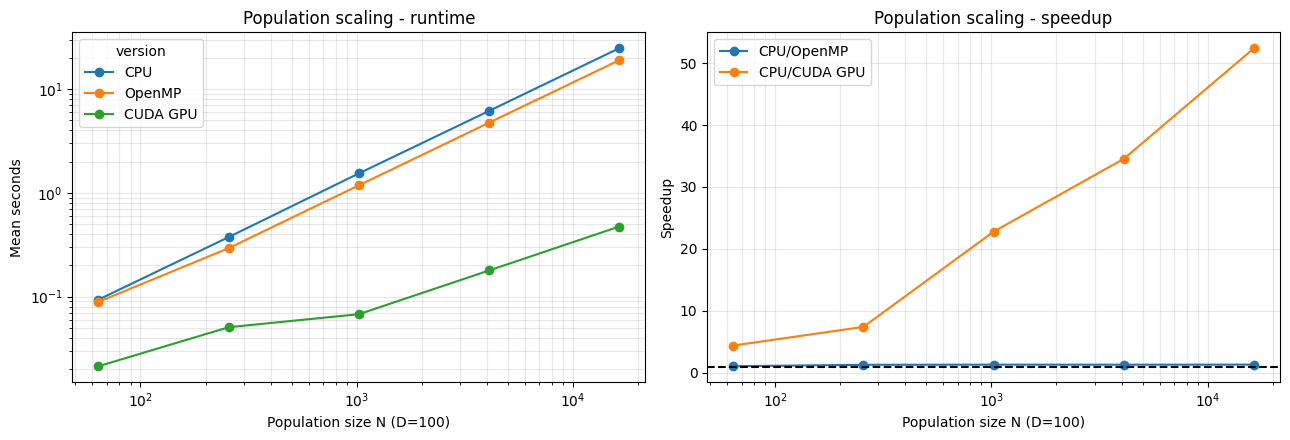

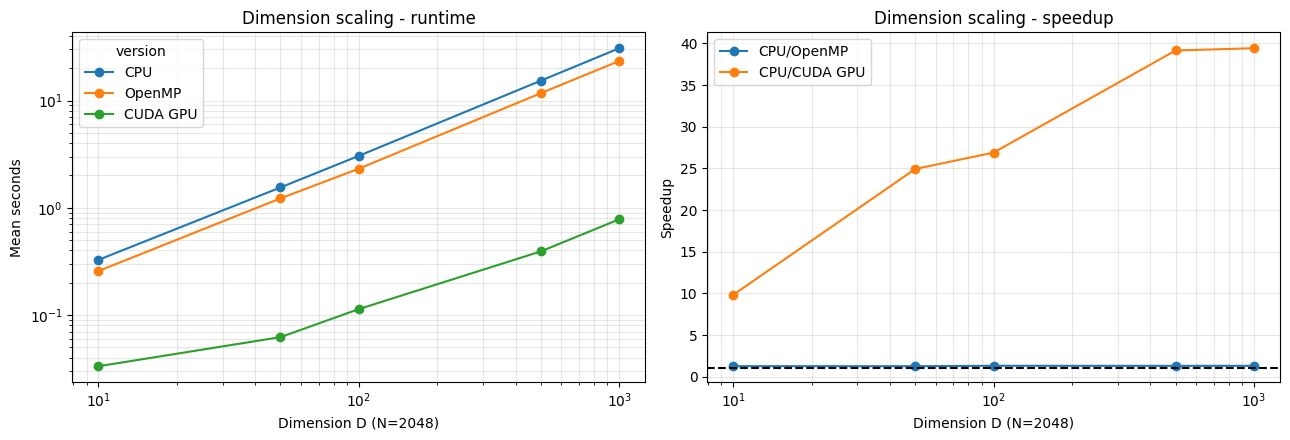

version,seq,omp,cuda
sweep,,,
64,0.093395,0.088931,0.021280
256,0.374402,0.292713,0.050592
1024,1.539233,1.181309,0.067565
4096,6.161094,4.748459,0.178382
16384,24.785872,18.993027,0.473033


version,seq,omp,cuda
sweep,,,
10,0.326526,0.256888,0.033216
50,1.546819,1.223010,0.062027
100,3.050892,2.315300,0.113402
500,15.331455,11.722952,0.391544
1000,30.774971,23.409883,0.780548


In [11]:
SCALE_FUNC = 3                       # F19 Rastrigin
POPS = [64, 256, 1024, 4096, 16384]  # add 65536 if you have time (sequential gets slow)
DIMS = [10, 50, 100, 500, 1000]
SCALE_ITERS, SCALE_RUNS = 100, 3

def sweep(var, values):
    rows = []
    for val in values:
        for v in IMPLS:
            kw = {var: val, "iters": SCALE_ITERS, "runs": SCALE_RUNS}
            if var == "dim": kw["pop"] = 2048
            if var == "pop": kw["dim"] = 100
            df = run(v, func=SCALE_FUNC, **kw); df["sweep"] = val; rows.append(df)
    out = pd.concat(rows, ignore_index=True); out["seconds"] = out["time_ms"] / 1000.0
    return out

pop_sweep = sweep("pop", POPS)
dim_sweep = sweep("dim", DIMS)

def plot_sweep(df, xlabel, title):
    t = df.groupby(["sweep", "version"])["seconds"].mean().unstack("version")[IMPLS]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    t.rename(columns=LABEL).plot(ax=axes[0], marker="o", logx=True, logy=True)
    axes[0].set_xlabel(xlabel); axes[0].set_ylabel("Mean seconds"); axes[0].set_title(title + " - runtime"); axes[0].grid(alpha=0.3, which="both")
    for v in IMPLS[1:]:
        (t["seq"] / t[v]).plot(ax=axes[1], marker="o", logx=True, label=f"CPU/{LABEL[v]}")
    axes[1].axhline(1, linestyle="--", color="k"); axes[1].set_xlabel(xlabel); axes[1].set_ylabel("Speedup")
    axes[1].set_title(title + " - speedup"); axes[1].legend(); axes[1].grid(alpha=0.3, which="both")
    plt.tight_layout(); plt.show()
    return t

t_pop = plot_sweep(pop_sweep, "Population size N (D=100)", "Population scaling")
t_dim = plot_sweep(dim_sweep, "Dimension D (N=2048)", "Dimension scaling")
display(t_pop); display(t_dim)
pop_sweep.to_csv("heo_pop_sweep.csv", index=False); dim_sweep.to_csv("heo_dim_sweep.csv", index=False)

## 8. Reporting checklist

* Report CPU/GPU model, OpenMP thread count, dimension, population, iterations, repeats, mean runtime, speedup and mean/std best score.
* Keep `ITERS` and `REPEATS` identical for all implementations; compare end-to-end wall-clock time.
* Best scores are stochastic and will not reach the known optimum; runtime alone does not establish optimization quality, so always read the speedup next to the score tables.
* The OpenMP version parallelises candidate generation, evaluation, sorting and gathering; the CUDA version additionally keeps all data on the device.
* **Reproducing the paper:** the paper reports HEO beating 29 algorithms, but its own tables show weak results on several shifted CEC 2015 functions, a welded-beam solution violating 3 of 7 constraints, and comparisons that reuse numbers from earlier papers without statistical tests. This notebook measures *parallel performance and implementation parity*; it does not validate the paper's quality claims.
* Try `-DHEO_LITERAL_SCALE` (edit the compile cell), `--levy-scale`, or `-DUSE_FLOAT` to explore variants.